# 02 — Results analysis

**Goal of this notebook:** turn the saved training results into the tables and figures of the
**Results and Discussion** section. Nothing is retrained here: we only read the CSV files written by
`src/train.py` and `src/run_experiments.py`.

Contents:
1. Multi-seed experiment: number of bins and decaying α (3 seeds × 20,000 episodes)
2. Learning curves (mean ± std over seeds)
3. Speed of learning (first goal) and final quality (greedy test)
4. Convergence analysis
5. Exploration experiment: ε starting at 1.0 vs 0.1 (single seed)
6. Comparison with the article

All figures are saved to `report/figures/`.

In [1]:
import glob
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RES = os.path.join("..", "results")
MULTI = os.path.join(RES, "multiseed")
FIG_DIR = os.path.join("..", "report", "figures")
os.makedirs(FIG_DIR, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})

# fixed colour per configuration (the same in every figure)
CONFIGS = {
    "bins12":            ("12 bins",            "#2a78d6"),
    "bins20":            ("20 bins",            "#eb6834"),
    "bins40":            ("40 bins",            "#1baf7a"),
    "bins20_alphadecay": ("20 bins + α decay",  "#6250d6"),
}
THRESHOLD = -110

## 1. Multi-seed experiment

Common settings: γ = 0.99, α = 0.1, ε decays linearly from 0.1 to 0.01 over the first half of training,
20,000 episodes, seeds 0, 1, 2. The `bins20_alphadecay` configuration also decays α from 0.1 to 0.01.

`greedy_mean` is the average reward of the final Q-table over 100 test episodes with ε = 0 — this is the
quantity that the "solved" criterion (≥ −110) refers to.

In [2]:
runs = pd.read_csv(os.path.join(MULTI, "summary_runs.csv"))
runs["label"] = runs["config"].map(lambda c: CONFIGS[c][0])
runs[["label", "seed", "first_goal", "train_last100", "greedy_mean", "greedy_std", "minutes"]].round(1)

,label,seed,first_goal,train_last100,greedy_mean,greedy_std,minutes
0,12 bins,0,259,-177.0,-199.7,3.3,5.0
1,12 bins,1,177,-168.1,-158.2,20.6,5.0
2,12 bins,2,148,-141.8,-138.2,27.3,5.0
3,20 bins,0,589,-139.3,-141.5,19.1,4.9
4,20 bins,1,432,-149.0,-149.6,12.8,4.9
5,20 bins,2,478,-144.7,-143.9,10.7,4.9
6,40 bins,0,1862,-129.5,-132.6,18.9,5.0
7,40 bins,1,1777,-133.1,-133.2,20.6,5.1
8,40 bins,2,1777,-160.3,-163.2,18.5,5.1
9,20 bins + α decay,0,508,-138.5,-139.7,19.1,4.8


In [3]:
summary = (runs.groupby("label", sort=False)[["first_goal", "train_last100", "greedy_mean"]]
             .agg(["mean", "std"]).round(1))
summary

first_goal        train_last100       greedy_mean      
                        mean    std          mean   std        mean   std
label                                                                    
12 bins                194.7   57.6        -162.3  18.3      -165.3  31.4
20 bins                499.7   80.7        -144.3   4.8      -145.0   4.2
40 bins               1805.3   49.1        -141.0  16.8      -143.0  17.5
20 bins + α decay      536.0  112.6        -137.0   5.4      -138.3   7.7

## 2. Learning curves

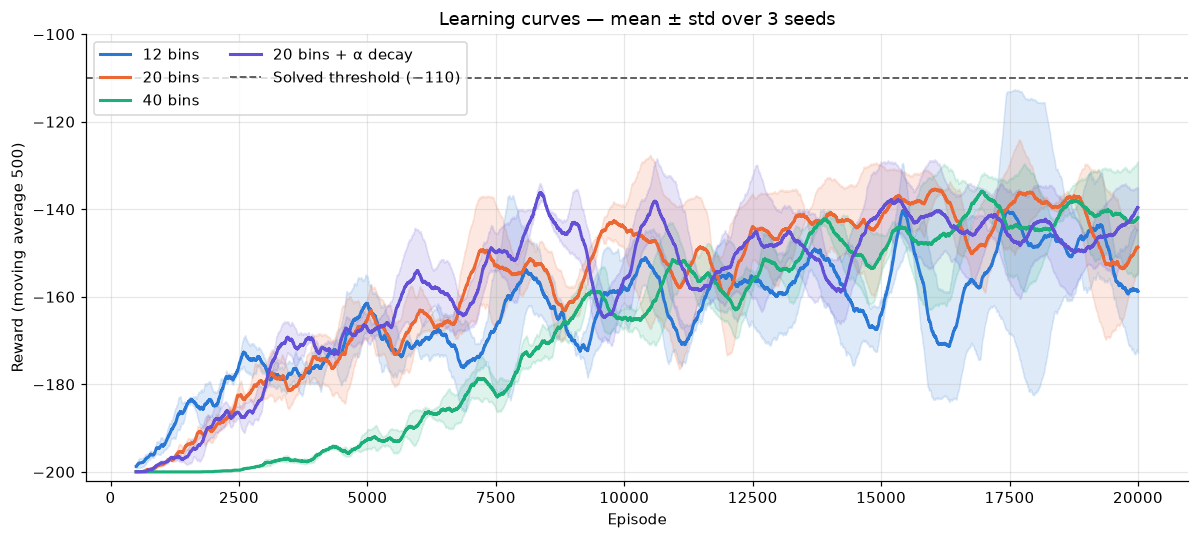

In [4]:
def load_returns(config):
    """Return an array (n_seeds, n_episodes) of rewards for one configuration."""
    files = sorted(glob.glob(os.path.join(MULTI, f"{config}_s*.csv")))
    return np.array([pd.read_csv(f)["reward"].to_numpy() for f in files])


returns = {c: load_returns(c) for c in CONFIGS}
WINDOW = 500

fig, ax = plt.subplots(figsize=(11, 5))
for c, (label, color) in CONFIGS.items():
    smooth = np.array([pd.Series(r).rolling(WINDOW).mean() for r in returns[c]])
    m, s = smooth.mean(axis=0), smooth.std(axis=0)
    x = np.arange(len(m))
    ax.plot(x, m, color=color, lw=2, label=label)
    ax.fill_between(x, m - s, m + s, color=color, alpha=0.15)
ax.axhline(THRESHOLD, color="#555", ls="--", lw=1.2, label="Solved threshold (−110)")
ax.set_xlabel("Episode"); ax.set_ylabel(f"Reward (moving average {WINDOW})")
ax.set_title("Learning curves — mean ± std over 3 seeds")
ax.set_ylim(-202, -100); ax.legend(loc="upper left", ncol=2); plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "results_learning_curves.png"), dpi=150); plt.show()

**Reading:**
- **12 bins** rises first: with only 144 states, every state is visited often, so values spread quickly.
- **40 bins** is the slowest to start (≈ 2,000 episodes at −200): 1,600 states take much longer to explore.
- After about 12,000 episodes all configurations level off between roughly **−140 and −160**, still below the
  −110 threshold.
- The shaded bands show how much the seeds disagree: they are widest for 12 bins.

## 3. Speed of learning vs. final quality

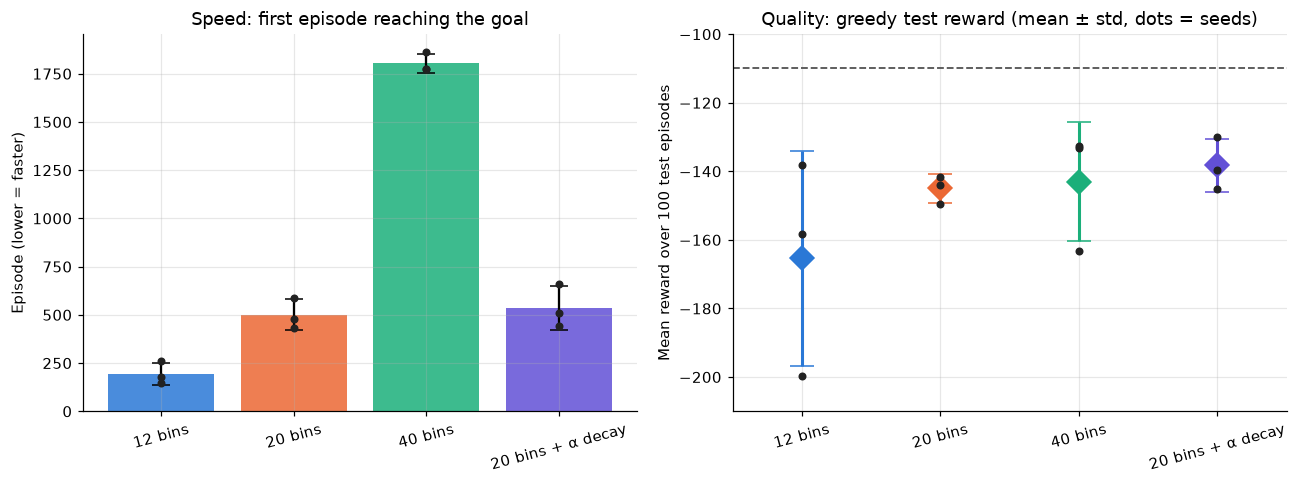

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
labels = [CONFIGS[c][0] for c in CONFIGS]
colors = [CONFIGS[c][1] for c in CONFIGS]

for ax, col, title, ylabel in [
    (axes[0], "first_goal", "Speed: first episode reaching the goal", "Episode (lower = faster)"),
    (axes[1], "greedy_mean", "Quality: greedy test reward (mean ± std, dots = seeds)", "Mean reward over 100 test episodes"),
]:
    g = runs.groupby("config", sort=False)[col]
    means, stds = g.mean().reindex(CONFIGS), g.std().reindex(CONFIGS)
    if col == "first_goal":
        ax.bar(labels, means, yerr=stds, color=colors, capsize=6, alpha=0.85)
    else:                                                # negative rewards: points, not bars
        for i, (m, sd, colr) in enumerate(zip(means, stds, colors)):
            ax.errorbar(i, m, yerr=sd, fmt="D", color=colr, markersize=11, capsize=8, lw=2)
        ax.set_xticks(range(len(labels)), labels); ax.set_xlim(-0.5, len(labels) - 0.5)
    for i, c in enumerate(CONFIGS):                      # individual seeds as dots
        vals = runs.loc[runs.config == c, col]
        ax.scatter([i] * len(vals), vals, color="#222", s=18, zorder=3)
    ax.set_title(title); ax.set_ylabel(ylabel); ax.tick_params(axis="x", rotation=15)
axes[1].axhline(THRESHOLD, color="#555", ls="--", lw=1.2)
axes[1].set_ylim(-210, -100)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "results_speed_vs_quality.png"), dpi=150); plt.show()

**Reading:** this figure shows the **resolution trade-off** of discretization.
- Fewer bins → the agent reaches the goal sooner (12 bins: ≈ 195 episodes; 40 bins: ≈ 1,800).
- But fewer bins → a coarser, less reliable policy: 12 bins has the worst and most variable greedy score
  (one seed only reaches about −200).
- 20 bins is the most consistent across seeds; decaying α gives the best mean, but the gain over plain 20 bins
  (≈ 7 points) is about one standard deviation, so with 3 seeds **it is not a significant difference**.

## 4. Convergence analysis

We define the **plateau** of a run as its mean reward over the last 1,000 episodes, and the
**convergence episode** as the first episode where the moving average (window 500) has covered 95% of the way
from −200 to that plateau. This tells us *when* learning stops making real progress.

In [6]:
def convergence_episode(rewards, window=500, frac=0.95, tail=1000):
    smooth = pd.Series(rewards).rolling(window).mean().to_numpy()
    plateau = rewards[-tail:].mean()
    target = -200 + frac * (plateau + 200)
    hit = np.where(smooth >= target)[0]
    return (int(hit[0]) if len(hit) else None), plateau


rows = []
for c, (label, _) in CONFIGS.items():
    for seed, r in enumerate(returns[c]):
        ep, plateau = convergence_episode(r)
        rows.append({"label": label, "seed": seed, "convergence_episode": ep, "plateau": plateau})
conv = pd.DataFrame(rows)
conv_summary = conv.groupby("label", sort=False)[["convergence_episode", "plateau"]].agg(["mean", "std"]).round(1)
conv_summary

convergence_episode         plateau      
                                 mean     std    mean   std
label                                                      
12 bins                        6656.3  1684.7  -155.5   7.0
20 bins                        5622.7  1233.6  -150.4  11.6
40 bins                       14511.0  4790.0  -141.6  13.9
20 bins + α decay              7421.7   963.7  -142.8   8.0

**Reading:** 20 bins converges first (≈ 5,600 episodes), 12 bins and 20 bins + α decay follow
(≈ 6,700 and ≈ 7,400), and 40 bins is by far the slowest (≈ 14,500 ± 4,800) — its curve is still rising at
the end, so more episodes may help it most. This table gives the convergence metric required by the project.
Compare it with the learning curves: a configuration that converges early to a poor plateau (few bins) is not better than one that converges
later to a higher plateau (more bins). The definition (95% of the way to the plateau) is our choice and should
be stated in the report.

## 5. Exploration experiment: ε starting at 1.0 vs 0.1 (single seed)

These runs come from `src/train.py` with 20 bins, α = 0.1, γ = 0.99, seed 0. The greedy test values were
printed by `train.py` at the end of each run and are copied here from the terminal output.

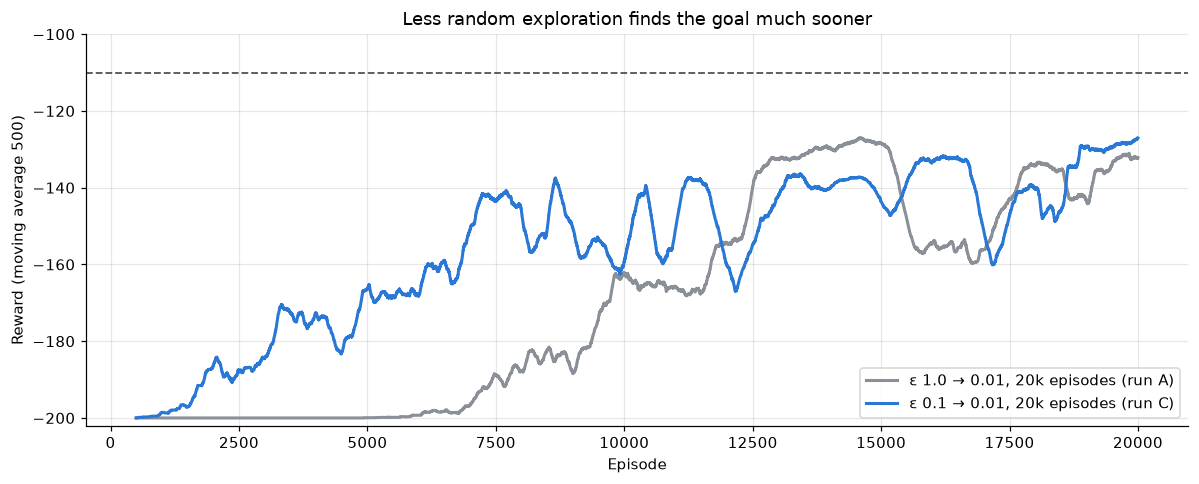

,run,first_goal,train_last100,greedy_test
0,"ε 1.0 → 0.01, 20k episodes (run A)",4933,-130.8,-192.9
1,"ε 0.1 → 0.01, 20k episodes (run C)",530,-124.3,-128.8


In [7]:
explore_runs = {
    "ε 1.0 → 0.01, 20k episodes (run A)": ("returns_bins20_a0.1_g0.99_e1.0_ep20000_s0.csv", -192.9, "#8A8F98"),
    "ε 0.1 → 0.01, 20k episodes (run C)": ("returns_bins20_a0.1_g0.99_e0.1_ep20000_s0.csv", -128.8, "#2a78d6"),
}

fig, ax = plt.subplots(figsize=(11, 4.5))
rows = []
for label, (fname, greedy, color) in explore_runs.items():
    r = pd.read_csv(os.path.join(RES, fname))["reward"].to_numpy()
    ax.plot(pd.Series(r).rolling(500).mean(), color=color, lw=2, label=label)
    first = int(np.argmax(r > -200)) if (r > -200).any() else None
    rows.append({"run": label, "first_goal": first, "train_last100": r[-100:].mean(), "greedy_test": greedy})
ax.axhline(THRESHOLD, color="#555", ls="--", lw=1.2)
ax.set_xlabel("Episode"); ax.set_ylabel("Reward (moving average 500)")
ax.set_title("Less random exploration finds the goal much sooner")
ax.set_ylim(-202, -100); ax.legend(loc="lower right"); plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "results_exploration.png"), dpi=150); plt.show()
pd.DataFrame(rows).round(1)

**Reading:** starting with ε = 1.0 wastes thousands of episodes acting randomly — and we showed in notebook 01
that random actions never reach the flag. With ε = 0.1 the agent relies mostly on its Q-table, which starts
at 0 while every reward is −1: untried actions look better than tried ones (**optimistic initialisation**), so the
agent explores systematically and reaches the goal about 9× sooner. This is a single seed: it shows the effect,
the multi-seed runs confirm the size of it.

## 6. Comparison with the article

In [8]:
comparison = pd.DataFrame({
    "Source": ["Article (Table II, best)", "Article (Table II, best)", "Ours (3 seeds)", "Ours (3 seeds)"],
    "Bins": [12, 12, 12, 20],
    "Setting": ["α 0.008, decay 100", "α 0.008, decay 10", "α 0.1, ε 0.1→0.01", "α 0.1→0.01, ε 0.1→0.01"],
    "Reported score": ["−108", "−109",
                       f"{runs.loc[runs.config=='bins12','greedy_mean'].mean():.0f} ± {runs.loc[runs.config=='bins12','greedy_mean'].std():.0f}",
                       f"{runs.loc[runs.config=='bins20_alphadecay','greedy_mean'].mean():.0f} ± {runs.loc[runs.config=='bins20_alphadecay','greedy_mean'].std():.0f}"],
    "Evaluation": ["1 run, training score", "1 run, training score",
                   "greedy test, 100 episodes", "greedy test, 100 episodes"],
})
comparison

,Source,Bins,Setting,Reported score,Evaluation
0,"Article (Table II, best)",12,"α 0.008, decay 100",−108,"1 run, training score"
1,"Article (Table II, best)",12,"α 0.008, decay 10",−109,"1 run, training score"
2,Ours (3 seeds),12,"α 0.1, ε 0.1→0.01",-165 ± 31,"greedy test, 100 episodes"
3,Ours (3 seeds),20,"α 0.1→0.01, ε 0.1→0.01",-138 ± 8,"greedy test, 100 episodes"


**Reading:** our settings are not identical to the article's (we use α = 0.1; the article's "decay" is not
defined), so this is not an exact reproduction yet — that is the next experiment (reproducing Table II over
5 seeds). But the gap is large: with the same 12 bins we obtain −165 ± 31 on a greedy test, far from −108. A
single run plus a training-time score can easily look much better than the policy really is.

---
### Summary for the report
- **Bins trade-off:** fewer bins learn faster, more bins give a better and more stable policy.
- **Plateau:** with 20,000 episodes no configuration reaches −110; the best is 20 bins + decaying α
  (≈ −138 ± 8).
- **Exploration:** starting ε at 0.1 instead of 1.0 reaches the goal about 9× sooner (single seed).
- **Reliability:** results vary up to ±31 between seeds — conclusions need several seeds and a greedy test.
- Figures saved: `results_learning_curves.png`, `results_speed_vs_quality.png`, `results_exploration.png`.